<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [NBA Basketball Data](https://github.com/Query-farm/vgi-nba)

Standings, scores, schedules, box scores, play-by-play, and player and team stats.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nba/blob/main/notebooks/03_keep_rate_units_and_rank_populations.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nba/blob/main/notebooks/README.md)


## A ranking belongs to a metric and a population

**Does the top scoring rate remain first after a games-played requirement, and does a team seed imply the highest net rating?** Join three small synthetic season snapshots within each league namespace. Keep win-based rank, points per game and points per 100 possessions separate; then apply one local eligibility rule.

**Entirely synthetic local API scenario.** All people, teams, identifiers and
observations below are fictional. Three league schemas exercise the real released
worker's parsers; these are not NBA, WNBA or G League records, rankings or performance
comparisons. The first notebook separately preserves a tiny genuine recorded response.
The helper only serves declared JSON envelopes, with exact request audits; all
joins, measures and selections remain visible SQL. Identical numeric IDs deliberately
appear in different schemas, so **league plus ID** is the join key.

### Choose one local rule

`MIN_GAMES` is an integer 1–10. The default, 5, excludes a four-game player from the local comparison; experiment, 1, includes that player. The returned leaderboard rank remains visible and is never relabeled as the rank after our filter.

In [1]:
MIN_GAMES = 5

In [2]:
import importlib.metadata

try:
    _shared_version = importlib.metadata.version("vgi-example-notebooks")
except importlib.metadata.PackageNotFoundError:
    _shared_version = None
if _shared_version != "0.3.47":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.47"
from vgi_notebooks import check_runtime
from vgi_notebooks.bootstrap import prepare

check_runtime()
_companion_directory = prepare("nba")

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from nba_examples import NBAExample

if type(MIN_GAMES) is not int or not 1 <= MIN_GAMES <= 10:
    raise ValueError("MIN_GAMES must be an integer from 1 through 10")
source = NBAExample("synthetic", "rates")
theme()
session = connect(globals())
SOURCE = "Synthetic miniature · fictional inputs · NBA worker v0.2.0"
LEAGUE_LABELS = {"nba": "NBA", "wnba": "WNBA", "gleague": "G League"}

### Attach the released worker

The tag owns worker dependencies inside an isolated Python 3.13 environment.
Shared base tooling preserves the notebook kernel and initializes UTC plus an empty
temporary SQL-secret store with persistence disabled. First use requires Git/network
for packages and the VGI extension; these synthetic examples contact only loopback
for data. No live dataset is downloaded or substituted.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nba' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-nba@v0.2.0 vgi-nba');

,Success


### Compare team measures at a common season grain

Materialize `standings`, `team_stats` and `advanced_team_stats` for season start 2025
in all three schemas. NBA/G League return 2025–26; WNBA returns 2025. The first supplies
win/loss record and seed, the second points **per game**, and the third net rating
in **points per 100 possessions** plus pace. Those quantities have different
units and cannot be ranked interchangeably. Three fictional teams are a cohort,
not a complete league; no sum of wins/losses is asserted for the full competition.

In [5]:
%%sql
CREATE TABLE standings_nba AS SELECT * FROM nba.nba.standings(season:=2025);
CREATE TABLE standings_wnba AS SELECT * FROM nba.wnba.standings(season:=2025);
CREATE TABLE standings_gleague AS SELECT * FROM nba.gleague.standings(season:=2025);
CREATE TABLE standings AS SELECT 'nba' AS league,* FROM standings_nba UNION ALL SELECT 'wnba' AS league,* FROM standings_wnba UNION ALL SELECT 'gleague' AS league,* FROM standings_gleague;
CREATE TABLE team_base_nba AS SELECT * FROM nba.nba.team_stats(season:=2025,per_mode:='PerGame');
CREATE TABLE team_base_wnba AS SELECT * FROM nba.wnba.team_stats(season:=2025,per_mode:='PerGame');
CREATE TABLE team_base_gleague AS SELECT * FROM nba.gleague.team_stats(season:=2025,per_mode:='PerGame');
CREATE TABLE team_base AS SELECT 'nba' AS league,* FROM team_base_nba UNION ALL SELECT 'wnba' AS league,* FROM team_base_wnba UNION ALL SELECT 'gleague' AS league,* FROM team_base_gleague;
CREATE TABLE team_advanced_nba AS SELECT * FROM nba.nba.advanced_team_stats(season:=2025);
CREATE TABLE team_advanced_wnba AS SELECT * FROM nba.wnba.advanced_team_stats(season:=2025);
CREATE TABLE team_advanced_gleague AS SELECT * FROM nba.gleague.advanced_team_stats(season:=2025);
CREATE TABLE team_advanced AS SELECT 'nba' AS league,* FROM team_advanced_nba UNION ALL SELECT 'wnba' AS league,* FROM team_advanced_wnba UNION ALL SELECT 'gleague' AS league,* FROM team_advanced_gleague;

,Count


In [6]:
%%sql team_frame <<
SELECT s.league,s.season,s.team_id,s.team_name,s.playoff_rank AS returned_seed,
 s.wins,s.losses,s.win_percentage,b.points AS points_per_game,b.per_mode,
 a.offensive_rating,a.defensive_rating,a.net_rating,a.pace,
 dense_rank() OVER(PARTITION BY s.league ORDER BY a.net_rating DESC) AS cohort_net_rank
FROM standings s JOIN team_base b USING(league,season,season_type,team_id)
JOIN team_advanced a USING(league,season,season_type,team_id)
ORDER BY s.league,s.playoff_rank;

,league,season,team_id,team_name,returned_seed,wins,losses,win_percentage,points_per_game,per_mode,offensive_rating,defensive_rating,net_rating,pace,cohort_net_rank
0,gleague,2025-26,7001,Alpha,1,8,2,0.8,102.0,PerGame,109.0,110.0,-1.0,99.0,3
1,gleague,2025-26,7002,Birch,2,6,4,0.6,106.0,PerGame,112.0,110.0,2.0,100.0,2
2,gleague,2025-26,7003,Cedar,3,4,6,0.4,100.0,PerGame,115.0,110.0,5.0,101.0,1
3,nba,2025-26,7001,Alpha,1,8,2,0.8,100.0,PerGame,112.0,110.0,2.0,95.0,2
4,nba,2025-26,7002,Birch,2,6,4,0.6,104.0,PerGame,115.0,110.0,5.0,96.0,1
5,nba,2025-26,7003,Cedar,3,4,6,0.4,98.0,PerGame,109.0,110.0,-1.0,97.0,3
6,wnba,2025,7001,Alpha,1,8,2,0.8,101.0,PerGame,115.0,110.0,5.0,97.0,1
7,wnba,2025,7002,Birch,2,6,4,0.6,105.0,PerGame,109.0,110.0,-1.0,98.0,3
8,wnba,2025,7003,Cedar,3,4,6,0.4,99.0,PerGame,112.0,110.0,2.0,99.0,2


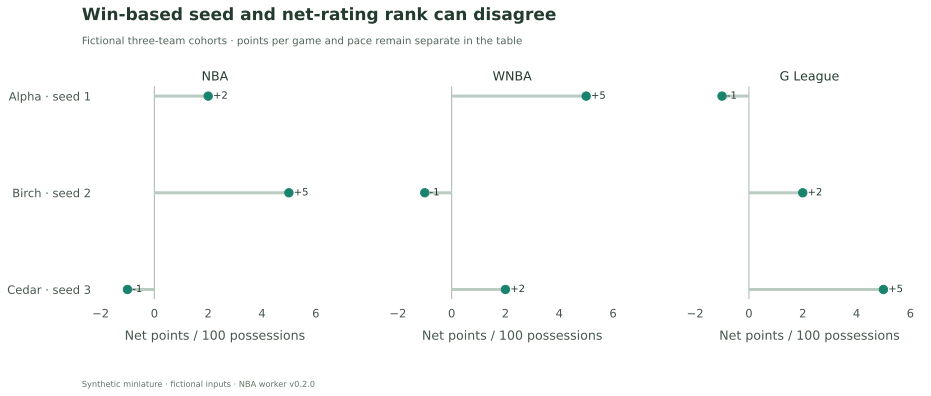

**6 of 9** team rows have a returned seed different from their net-rating rank within this tiny cohort. Points per game and pace are retained as context; neither converts a seed into a possession-adjusted ranking.

In [7]:
display(team_frame)
fig, axes = plt.subplots(1, 3, figsize=(13, 5.8), sharex=True, sharey=True)
for ax, league in zip(axes, ["nba", "wnba", "gleague"], strict=True):
    rows = team_frame[team_frame.league == league].sort_values("returned_seed")
    y = np.arange(len(rows))
    ax.axvline(0, color="#A8B6AE", lw=1)
    ax.hlines(y, 0, rows.net_rating, color="#BACBC1", lw=3)
    ax.scatter(rows.net_rating, y, color="#19836D", s=70, zorder=3)
    ax.set_yticks(y, [f"{r.team_name} · seed {r.returned_seed}" for r in rows.itertuples()])
    ax.invert_yaxis()
    ax.set_xlim(-2, 6.5)
    ax.set_title(LEAGUE_LABELS[league])
    ax.set_xlabel("Net points / 100 possessions")
    for j, row in enumerate(rows.itertuples()):
        ax.text(row.net_rating + 0.18, j, f"{row.net_rating:+g}", va="center", fontsize=10)
finish(
    fig,
    "Win-based seed and net-rating rank can disagree",
    "Fictional three-team cohorts · points per game and pace remain separate in the table",
    SOURCE,
    name="team-rank-context",
)
disagreements = int((team_frame.returned_seed != team_frame.cohort_net_rank).sum())
prose(
    f"**{disagreements} of {len(team_frame)}** team rows have a returned seed different from "
    "their net-rating rank within this tiny cohort. Points per game and pace are retained "
    "as context; neither converts a seed into a possession-adjusted ranking."
)

### Keep returned leaderboard rank beside a local eligibility rule

`player_stats` supplies points per game and games played; `advanced_player_stats`
supplies true-shooting and usage fractions; `league_leaders` supplies the provider's
returned points ranking. Join by league, season, season type and player ID. First
verify that points and games agree across the two rate sources, then apply our
minimum-games rule. It is a teaching filter, not an official league qualification.
True-shooting percentage is an efficiency estimate, not a probability of winning.
A higher rate after four games is not interchangeable with evidence from ten.

In [8]:
%%sql
CREATE TABLE player_base_nba AS SELECT * FROM nba.nba.player_stats(season:=2025,per_mode:='PerGame');
CREATE TABLE player_base_wnba AS SELECT * FROM nba.wnba.player_stats(season:=2025,per_mode:='PerGame');
CREATE TABLE player_base_gleague AS SELECT * FROM nba.gleague.player_stats(season:=2025,per_mode:='PerGame');
CREATE TABLE player_base AS SELECT 'nba' AS league,* FROM player_base_nba UNION ALL SELECT 'wnba' AS league,* FROM player_base_wnba UNION ALL SELECT 'gleague' AS league,* FROM player_base_gleague;
CREATE TABLE player_advanced_nba AS SELECT * FROM nba.nba.advanced_player_stats(season:=2025);
CREATE TABLE player_advanced_wnba AS SELECT * FROM nba.wnba.advanced_player_stats(season:=2025);
CREATE TABLE player_advanced_gleague AS SELECT * FROM nba.gleague.advanced_player_stats(season:=2025);
CREATE TABLE player_advanced AS SELECT 'nba' AS league,* FROM player_advanced_nba UNION ALL SELECT 'wnba' AS league,* FROM player_advanced_wnba UNION ALL SELECT 'gleague' AS league,* FROM player_advanced_gleague;
CREATE TABLE leaders_nba AS SELECT * FROM nba.nba.league_leaders(season:=2025,stat_category:='PTS',per_mode:='PerGame');
CREATE TABLE leaders_wnba AS SELECT * FROM nba.wnba.league_leaders(season:=2025,stat_category:='PTS',per_mode:='PerGame');
CREATE TABLE leaders_gleague AS SELECT * FROM nba.gleague.league_leaders(season:=2025,stat_category:='PTS',per_mode:='PerGame');
CREATE TABLE leaders AS SELECT 'nba' AS league,* FROM leaders_nba UNION ALL SELECT 'wnba' AS league,* FROM leaders_wnba UNION ALL SELECT 'gleague' AS league,* FROM leaders_gleague;

,Count


In [9]:
%%sql player_frame <<
SELECT b.league,b.season,b.player_id,b.player_name,b.games_played,b.points AS points_per_game,
 b.per_mode,a.true_shooting_percentage,a.usage_percentage,l.rank AS returned_rank,
 l.points AS leaderboard_points,l.games_played AS leaderboard_games,
 b.games_played>={{ MIN_GAMES }} AS selected
FROM player_base b JOIN player_advanced a USING(league,season,season_type,player_id)
JOIN leaders l USING(league,season,season_type,player_id)
ORDER BY b.league,l.rank;

,league,season,player_id,player_name,games_played,points_per_game,per_mode,true_shooting_percentage,usage_percentage,returned_rank,leaderboard_points,leaderboard_games,selected
0,gleague,2025-26,9001,Ada Vale,4,32.0,PerGame,0.65,0.35,1,32.0,4,False
1,gleague,2025-26,9002,Bea North,10,26.0,PerGame,0.55,0.25,2,26.0,10,True
2,gleague,2025-26,9003,Cam Drift,10,22.0,PerGame,0.60,0.20,3,22.0,10,True
3,nba,2025-26,9001,Ada Vale,4,30.0,PerGame,0.65,0.35,1,30.0,4,False
4,nba,2025-26,9002,Bea North,10,24.0,PerGame,0.55,0.25,2,24.0,10,True
5,nba,2025-26,9003,Cam Drift,10,20.0,PerGame,0.60,0.20,3,20.0,10,True
6,wnba,2025,9001,Ada Vale,4,31.0,PerGame,0.65,0.35,1,31.0,4,False
7,wnba,2025,9002,Bea North,10,25.0,PerGame,0.55,0.25,2,25.0,10,True
8,wnba,2025,9003,Cam Drift,10,21.0,PerGame,0.60,0.20,3,21.0,10,True


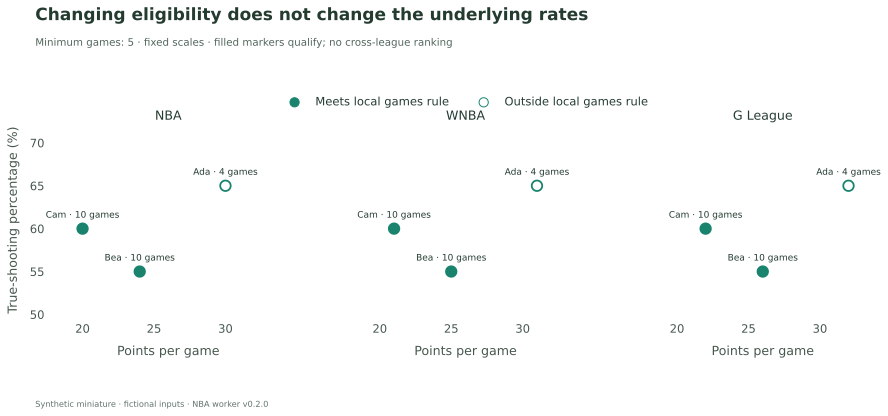

**6 of 9** fictional player rows meet the local rule. **3** returned rank-one rows are excluded. Their ranks and rates remain visible, so selection is not confused with reranking.

In [10]:
display(player_frame)
fig, axes = plt.subplots(1, 3, figsize=(13, 6.1), sharex=True, sharey=True)
for ax, league in zip(axes, ["nba", "wnba", "gleague"], strict=True):
    rows = player_frame[player_frame.league == league]
    for row in rows.itertuples():
        ax.scatter(
            row.points_per_game,
            100 * row.true_shooting_percentage,
            s=110,
            facecolor="#19836D" if row.selected else "white",
            edgecolor="#19836D",
            linewidth=1.8,
            zorder=3,
        )
        ax.annotate(
            f"{row.player_name.split()[0]} · {row.games_played} games",
            (row.points_per_game, 100 * row.true_shooting_percentage),
            xytext=(0, 11),
            textcoords="offset points",
            ha="center",
            fontsize=9,
        )
    ax.set_title(LEAGUE_LABELS[league])
    ax.set_xlim(18, 34)
    ax.set_ylim(50, 72)
    ax.set_xlabel("Points per game")
axes[0].set_ylabel("True-shooting percentage (%)")
axes[0].scatter([], [], s=85, facecolor="#19836D", edgecolor="#19836D", label="Meets local games rule")
axes[0].scatter([], [], s=85, facecolor="white", edgecolor="#19836D", label="Outside local games rule")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.53, 0.79), ncol=2)
finish(
    fig,
    "Changing eligibility does not change the underlying rates",
    f"Minimum games: {MIN_GAMES} · fixed scales · filled markers qualify; no cross-league ranking",
    SOURCE,
    name=f"player-population-{MIN_GAMES}",
)
selected = player_frame[player_frame.selected]
prose(
    f"**{len(selected)} of {len(player_frame)}** fictional player rows meet the local rule. "
    f"**{int(((player_frame.returned_rank == 1) & ~player_frame.selected).sum())}** returned rank-one rows "
    "are excluded. Their ranks and rates remain visible, so selection is not confused with reranking."
)

### Check units, identity and population

Rows are joined within league and season. The validations compare corresponding metrics, not unlike units.

In [11]:
%%sql checks <<
SELECT 'nine distinct team keys' AS check_name,count(*)=9 AND count(*)=count(DISTINCT(league,season,team_id)) AS passed FROM standings
UNION ALL SELECT 'nine distinct player keys',count(*)=9 AND count(*)=count(DISTINCT(league,season,player_id)) FROM player_base
UNION ALL SELECT 'per-game units preserved',NOT EXISTS(SELECT 1 FROM team_base WHERE per_mode<>'PerGame') AND NOT EXISTS(SELECT 1 FROM player_base WHERE per_mode<>'PerGame')
UNION ALL SELECT 'team points agree with standings',NOT EXISTS(SELECT 1 FROM standings s JOIN team_base b USING(league,season,team_id)WHERE s.points_per_game<>b.points)
UNION ALL SELECT 'team games match record',NOT EXISTS(SELECT 1 FROM team_base WHERE games_played<>wins+losses)
UNION ALL SELECT 'net rating is offense minus defense',NOT EXISTS(SELECT 1 FROM team_advanced WHERE abs(net_rating-(offensive_rating-defensive_rating))>1e-10)
UNION ALL SELECT 'leaderboard rates agree',NOT EXISTS(SELECT 1 FROM player_base b JOIN leaders l USING(league,season,player_id)WHERE b.points<>l.points OR b.games_played<>l.games_played)
UNION ALL SELECT 'advanced player exposure agrees',NOT EXISTS(SELECT 1 FROM player_base b JOIN player_advanced a USING(league,season,player_id)WHERE b.games_played<>a.games_played)
UNION ALL SELECT 'fractions retain their domain',NOT EXISTS(SELECT 1 FROM player_advanced WHERE true_shooting_percentage NOT BETWEEN 0 AND 1 OR usage_percentage NOT BETWEEN 0 AND 1)
UNION ALL SELECT 'three season-key namespaces',count(DISTINCT league)=3 AND count(DISTINCT season)=2 FROM player_base;

In [12]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + source.audit())
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-03.json").write_text(
    json.dumps(
        {
            "parameters": {"MIN_GAMES": MIN_GAMES},
            "team_frame": team_frame.to_dict("records"),
            "player_frame": player_frame.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,nine distinct team keys,True
1,nine distinct player keys,True
2,per-game units preserved,True
3,team points agree with standings,True
4,team games match record,True
5,net rating is offense minus defense,True
6,leaderboard rates agree,True
7,advanced player exposure agrees,True
8,fractions retain their domain,True
9,three season-key namespaces,True


**All 10 SQL checks passed.** Exactly 18 approved API requests; each once, all parameters matched.

8826

### Change one thing

Change **MIN_GAMES 5→1**. Three four-game players become eligible, so filled markers increase from six to nine. Their point rates, true-shooting values and returned ranks must stay unchanged, as must the entire team-context chart. This is a changed comparison population, not improved player performance.

In [13]:
assert not con.execute("SELECT * FROM duckdb_secrets()").fetchall()
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nba](https://github.com/Query-farm/vgi-nba)